#Import Libraries & Environment Set Up

---



In [1]:
import bigframes.pandas as bf
import pandas as pd
from pandas_gbq import read_gbq
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import matplotlib.dates as mdates
from matplotlib.dates import WeekdayLocator, MonthLocator, MO # MO represents Monday
from google.cloud import bigquery
import textwrap

client = bigquery.Client()
pd.set_option('display.max_colwidth', None)

#Get Data

##Event Bands

In [2]:
# Option if we want to make this into a function (would need to be slightly modified)
# Function to load events from CSV or BigQuery
def load_event_bands(source="csv", path_or_query=None, project_id=None):
    """
    Load event annotations from CSV or BigQuery.

    Parameters:
    - source: 'csv' or 'bq'
    - path_or_query: CSV file path or BigQuery SQL query string
    - project_id: GCP project ID (required if source='bq')

    Returns:
    - List of (start_date, end_date, event_label) tuples
    """
    if source == "csv":
        df = pd.read_csv(path_or_query, parse_dates=["start_date", "end_date"])
    elif source == "bq":
        if not project_id:
            raise ValueError("project_id must be specified when loading from BigQuery")
        df = read_gbq(path_or_query, project_id=project_id, dialect="standard")
        df['start_date'] = pd.to_datetime(df['start_date'])
        df['end_date'] = pd.to_datetime(df['end_date'])
    else:
        raise ValueError("Invalid source. Must be 'csv' or 'bq'.")

    return list(df.itertuples(index=False, name=None))

In [3]:
events_df = pd.read_csv('gs://sesame_lydia/gsc_key_dates.csv', parse_dates=['start_date', 'end_date'])
events_df

,start_date,end_date,event_description,exact_start_date,source
0,2024-05-14,2024-05-21,Initial AI Overviews Launch in the U.S. for logged-in users,Y,https://blog.google/products/search/generative-ai-google-search-may-2024/
1,2024-08-15,2024-08-22,"Expanded to 6 additional countries, including India, UK, and Canada",Y,https://blog.google/products/search/new-ways-to-connect-to-the-web-with-ai-overviews/
2,2024-10-28,2024-11-04,Rolled out to 100+ countries globally,Y,https://en.wikipedia.org/wiki/AI_Overviews
3,2025-03-05,2025-03-12,"Expanded to Teens and Signed-Out Users, starting in Europe",Y,https://blog.google/feed/were-bringing-the-helpfulness-of-ai-overviews-to-more-countries-in-europe/
4,2025-05-20,2025-05-27,"AI Mode + Global Expansion to 200+ Countries, enhanced experience",Y,https://blog.google/products/search/ai-overview-expansion-may-2025-update/


In [7]:
event_ranges = list(events_df.iloc[:,:3].itertuples(index=False, name=None))
event_ranges

[(Timestamp('2024-05-14 00:00:00'),
  Timestamp('2024-05-21 00:00:00'),
  'Initial AI Overviews Launch in the U.S. for logged-in users'),
 (Timestamp('2024-08-15 00:00:00'),
  Timestamp('2024-08-22 00:00:00'),
  'Expanded to 6 additional countries, including India, UK, and Canada'),
 (Timestamp('2024-10-28 00:00:00'),
  Timestamp('2024-11-04 00:00:00'),
  'Rolled out to 100+ countries globally'),
 (Timestamp('2025-03-05 00:00:00'),
  Timestamp('2025-03-12 00:00:00'),
  'Expanded to Teens and Signed-Out Users, starting in Europe'),
 (Timestamp('2025-05-20 00:00:00'),
  Timestamp('2025-05-27 00:00:00'),
  'AI Mode + Global Expansion to 200+ Countries, enhanced experience')]

# Define the reusable functions

In [4]:
def add_event_bands(ax, events, ypos=0.95, alpha=0.3, color='gray', fontsize=10, wrap_width=50):
  """
  Adds vertical shaded bands with labels to a time series plot.

  Parameters:
  - ax: matplotlib Axes
  - events: list of (start_date, end_date, label) tuples
  - ypos: y-position for label (in axis fraction coordinates)
  - alpha: opacity of shaded band
  - color: color of shaded region
  - fontsize: font size for label
  """
  for start, end, label in events:
    ax.axvspan(start, end, color=color, alpha=alpha)
    wrapped_label = "\n".join(textwrap.wrap(label, width=wrap_width))
    ax.text(
      x=start,
      y=ax.get_ylim()[1] * ypos,
      s=wrapped_label,
      fontsize=fontsize,
      rotation=90,
      verticalalignment='top',
      bbox=dict(facecolor='white', alpha=0.5, edgecolor='none')
    )


In [5]:
def _plot_series(series, series_name, ax, series_index=0, title_suffix="", events=False):
    palette = list(sns.palettes.mpl_palette('Dark2'))

    series = series.sort_values('data_date', ascending=True)

    xs = series['data_date']
    ys = series[series_name]

    ax.plot(xs, ys, label=series_name)
    #ax.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

    # Set dynamic title
    capitalized_series_name = series_name.capitalize()
    full_title = f"{capitalized_series_name} - {title_suffix}".strip()
    ax.set_title(full_title, fontsize=20)

    ax.set_xlabel('data_date')
    ax.set_ylabel(series_name)

    # Format x-axis
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.tick_params(axis='x', rotation=45)

    # Add the event bands and labels
    if events:
        add_event_bands(ax, events)


# Impressions

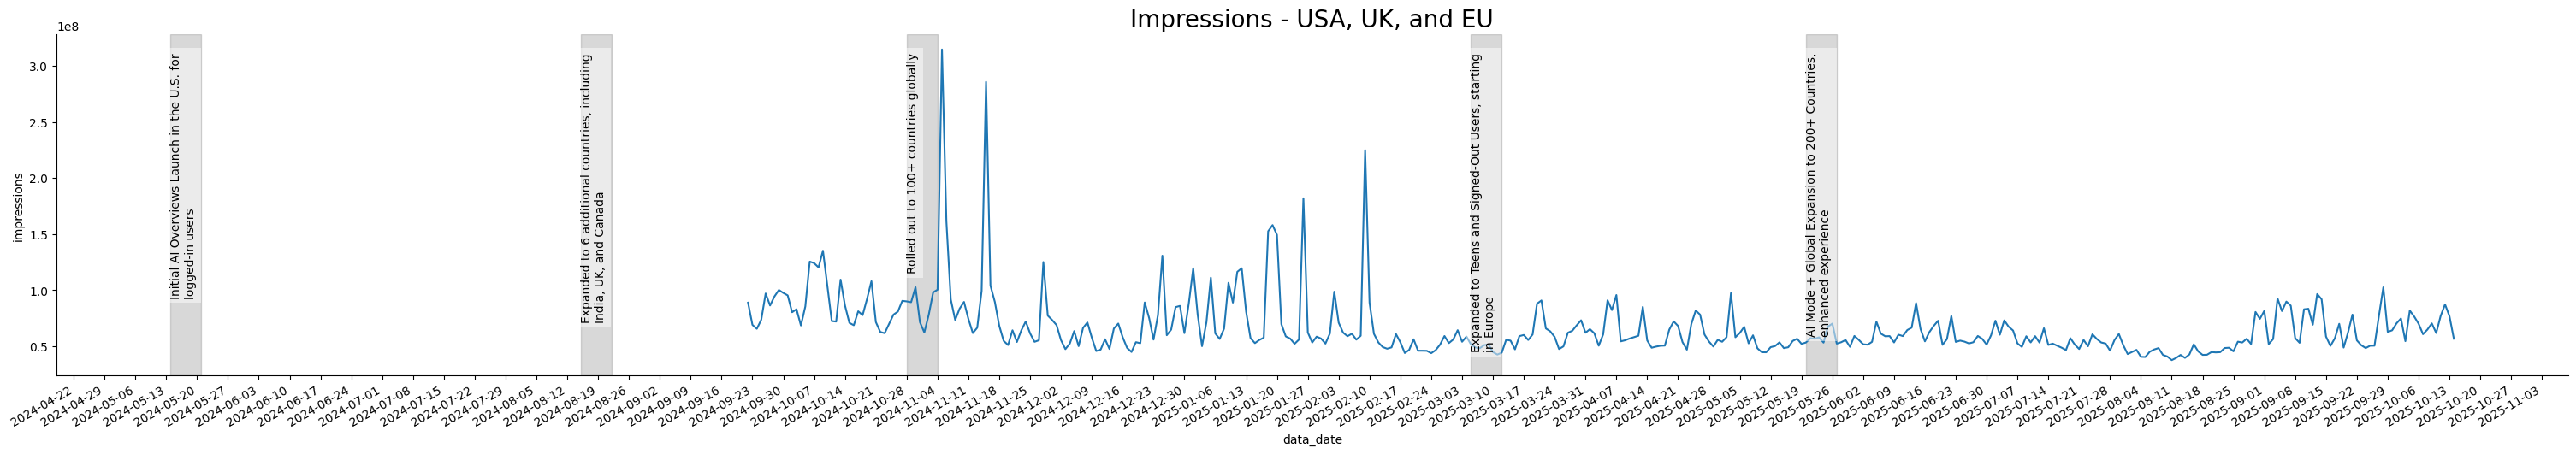

In [ ]:
# Get the number of impressions by date for USA, UK, and EU

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU

    WITH countries as
    (
      SELECT
          country_code
        --, country_name
      FROM `gannett-datascience.sesame.country_codes`
      WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    SELECT
        gsc.data_date
      , SUM(gsc.impressions) as impressions
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    JOIN countries
      ON gsc.country = countries.country_code
    WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
          gsc.search_type = 'WEB'
    GROUP BY
        gsc.data_date
    """
)

df_impressions = client.query_and_wait(query).to_dataframe()
df_impressions.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions, 'impressions', ax, title_suffix="USA, UK, and EU", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

In [ ]:
# @title
# All countries
# Get the number of impressions by date for USA, UK, and EU

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU

    WITH countries as
    (
      SELECT
          country_code
        --, country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    SELECT
        gsc.data_date
      , SUM(gsc.impressions) as impressions
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    JOIN countries
      ON gsc.country = countries.country_code
    WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
          gsc.search_type = 'WEB'
    GROUP BY
        gsc.data_date
    """
)

df_impressions_all = client.query_and_wait(query).to_dataframe()
df_impressions_all.head(5)

,data_date,impressions
0,2024-10-19,112078536
1,2024-11-27,69917188
2,2024-10-26,100434674
3,2025-07-10,68618623
4,2025-09-09,66204210


In [ ]:
df_impressions.describe()

,impressions
count,386.0
mean,67401885.896373
std,27991477.436814
min,37742808.0
25%,52429211.5
50%,59221573.0
75%,73374810.25
max,314583721.0


# All Countries

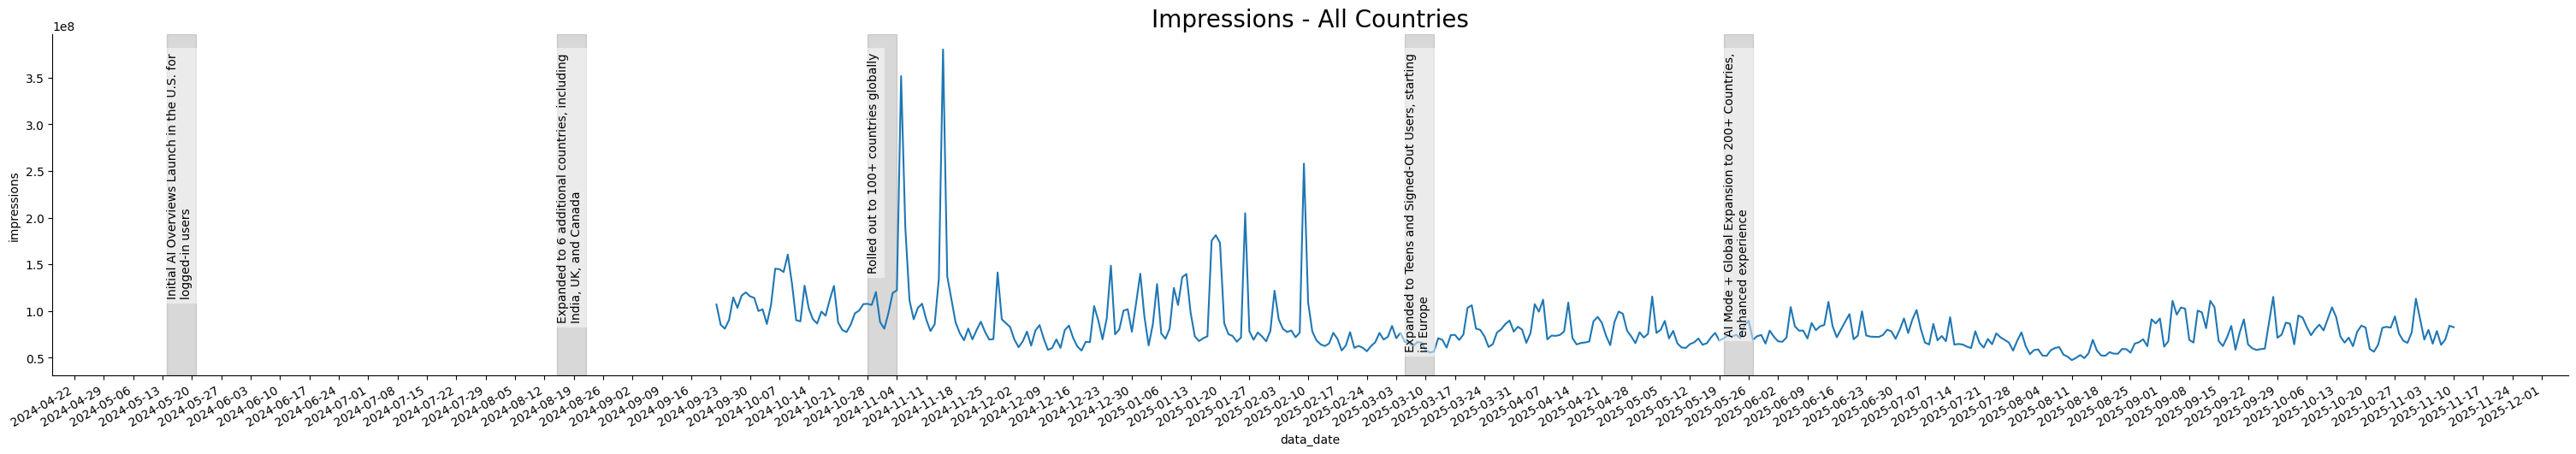

In [8]:
# Get the number of impressions by date for All countries

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU

    WITH countries as
    (
      SELECT
          country_code
        --, country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    SELECT
        gsc.data_date
      , SUM(gsc.impressions) as impressions
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    JOIN countries
      ON gsc.country = countries.country_code
    WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
          gsc.search_type = 'WEB'
    GROUP BY
        gsc.data_date
    """
)

df_impressions_all = client.query_and_wait(query).to_dataframe()
df_impressions_all.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_all, 'impressions', ax, title_suffix="All Countries", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

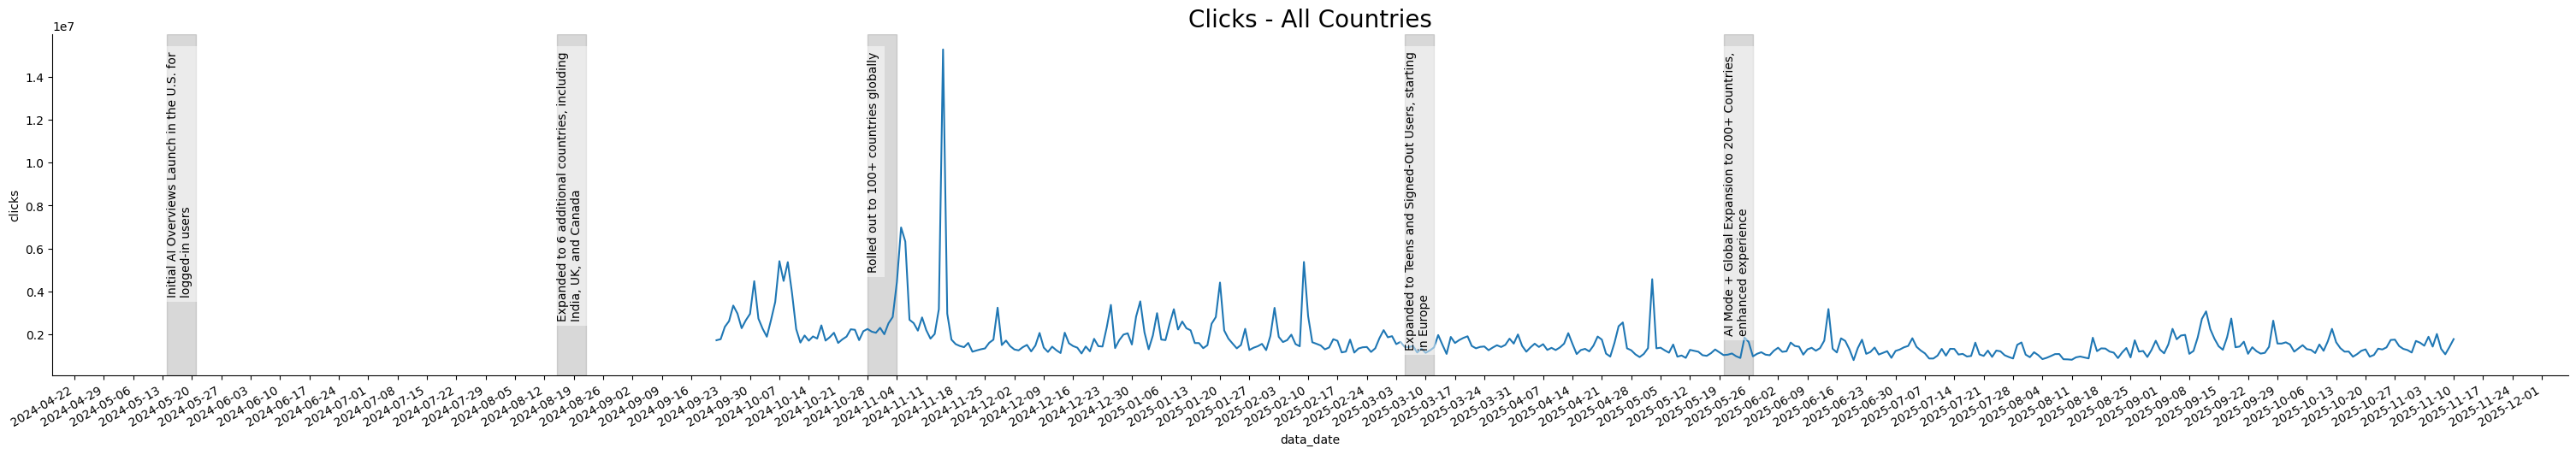

In [9]:
# Get the number of clicks by date for All countries

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU

    WITH countries as
    (
      SELECT
          country_code
        --, country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    SELECT
        gsc.data_date
      , SUM(gsc.clicks) as clicks
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    JOIN countries
      ON gsc.country = countries.country_code
    WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
          gsc.search_type = 'WEB'
    GROUP BY
        gsc.data_date
    """
)

df_impressions_all = client.query_and_wait(query).to_dataframe()
df_impressions_all.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_all, 'clicks', ax, title_suffix="All Countries", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

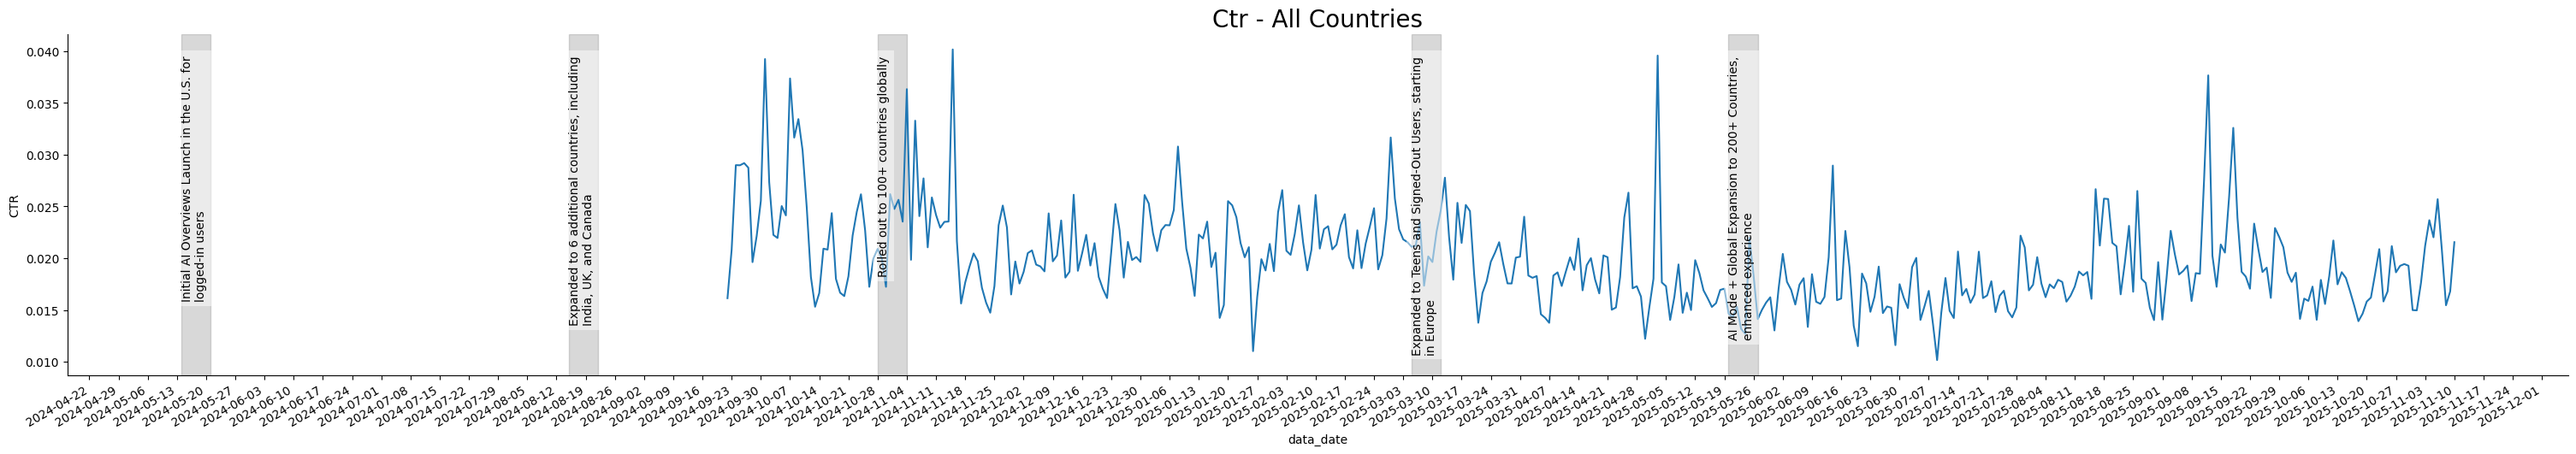

In [10]:
# Get the CTR by date for All countries

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU

    WITH countries as
    (
      SELECT
          country_code
        --, country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    SELECT
        gsc.data_date
      , SUM(clicks)/SUM(gsc.impressions) as CTR
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    JOIN countries
      ON gsc.country = countries.country_code
    WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
          gsc.search_type = 'WEB'
    GROUP BY
        gsc.data_date
    """
)

df_impressions_all = client.query_and_wait(query).to_dataframe()
df_impressions_all.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_all, 'CTR', ax, title_suffix="All Countries", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

<font color='red'>**!!!**</font>  
The expansion to teens and signed-out users looks like it might've affect the clickthrough rate

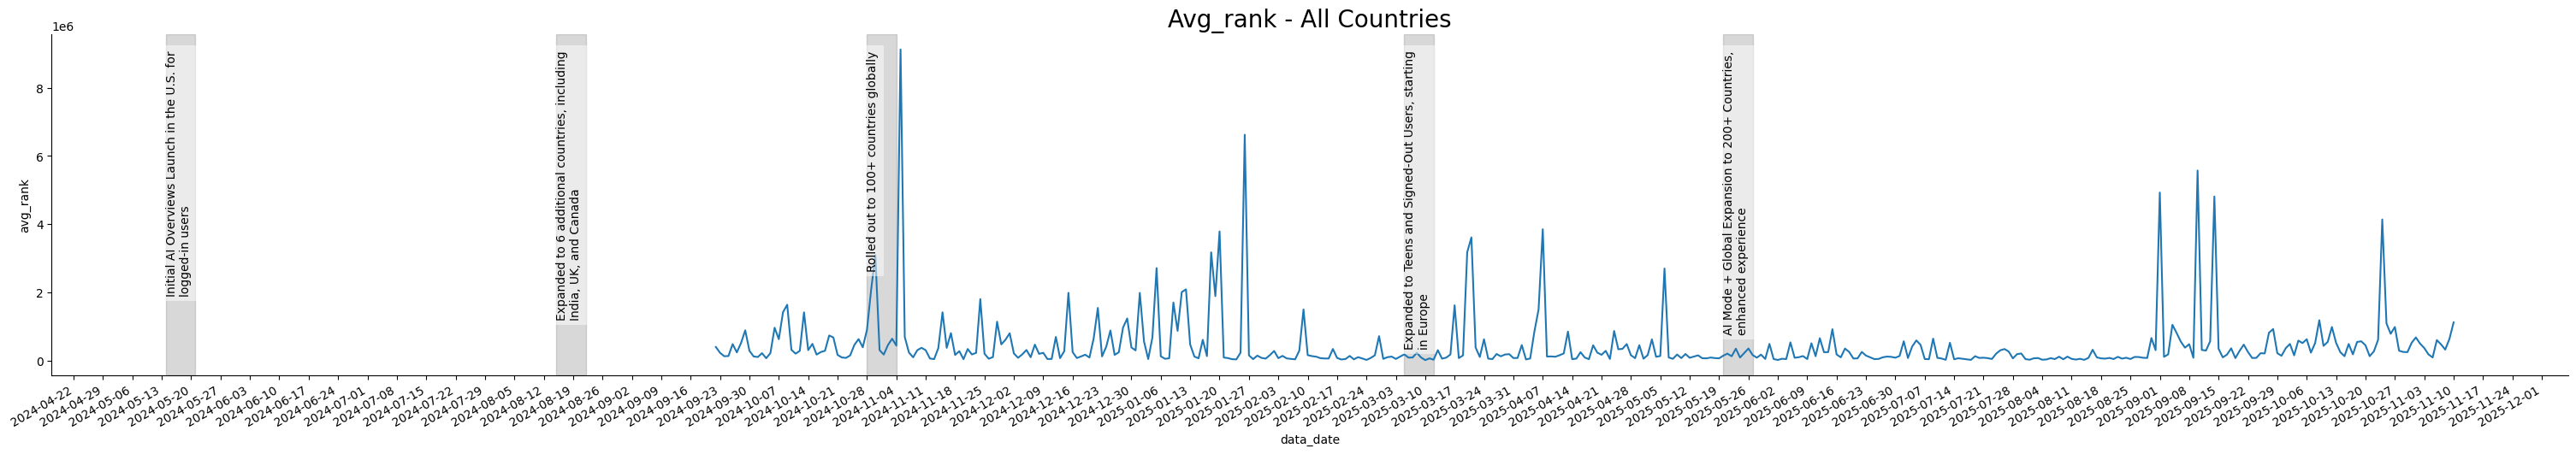

In [11]:
# Get the CTR by date for All countries

query = (
    """
    # Get the avg rank by date for USA, UK, and EU

    WITH countries as
    (
      SELECT
          country_code
        --, country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    SELECT
        gsc.data_date
      , (SUM(sum_position * impressions)) / SUM(impressions) as avg_rank
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    JOIN countries
      ON gsc.country = countries.country_code
    WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
          gsc.search_type = 'WEB'
    GROUP BY
        gsc.data_date
    """
)

df_impressions_all = client.query_and_wait(query).to_dataframe()
df_impressions_all.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_all, 'avg_rank', ax, title_suffix="All Countries", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

---
#Just Curious

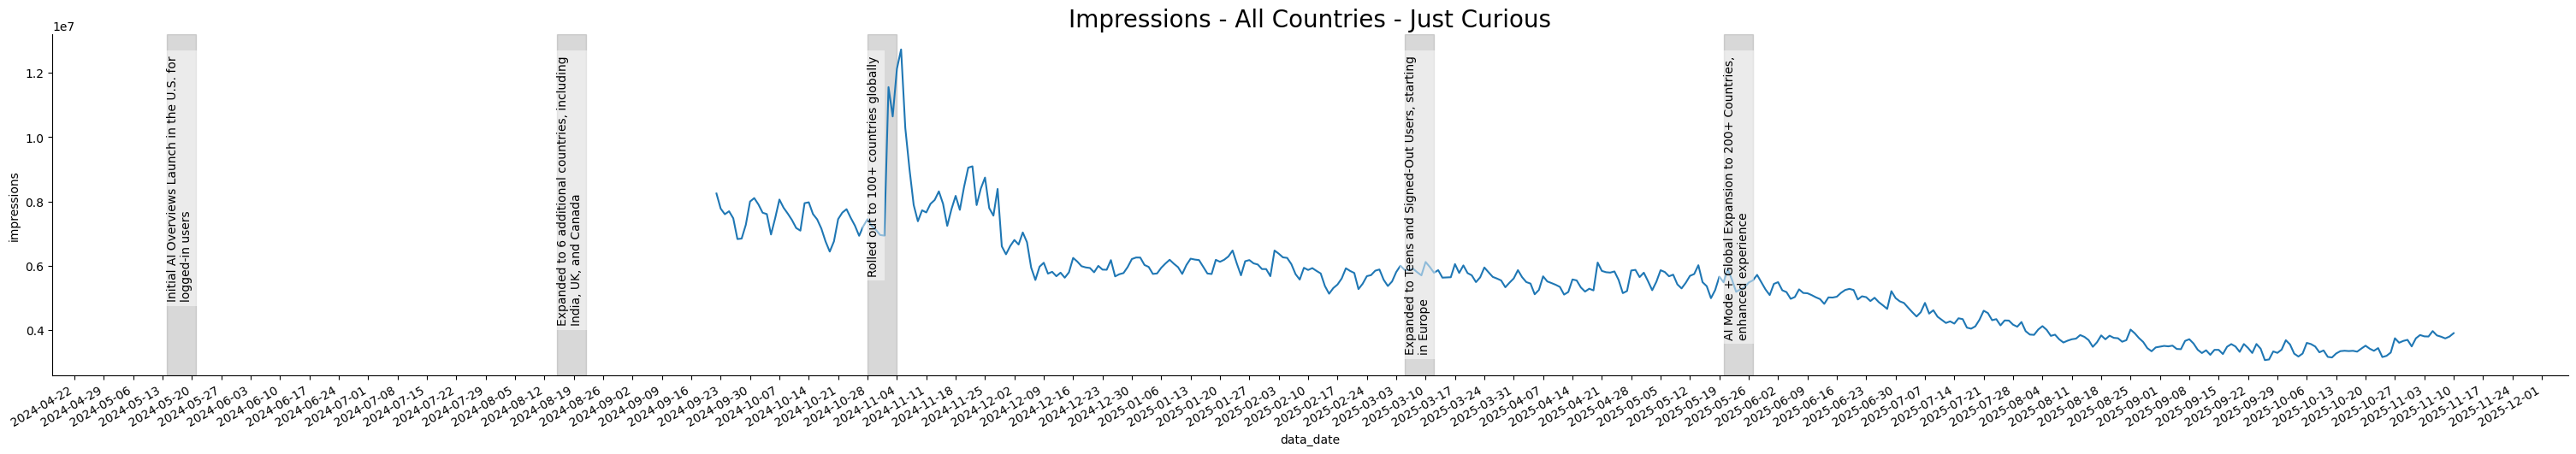

In [18]:
# Get the number of impressions by date for USA, UK, and EU

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU for Just Curious articles

    WITH countries as
    (
      SELECT
          country_code
          , geo_region
        , country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    , data as
    (
      SELECT
          gsc.data_date
        #, SUM(gsc.impressions) as impressions
        , impressions
        , country_code
        , country_name
        , geo_region
        , gsc.url
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN `gannett-datascience.sesame.just-curious-2025-09-29` jc
        ON gsc.url = jc.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
    )

    SELECT data_date
      , SUM(impressions) as impressions
    FROM data
    GROUP BY
        data_date
    ORDER BY data_date
    """
)

df_impressions_jc = client.query_and_wait(query).to_dataframe()
df_impressions_jc.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_jc, 'impressions', ax, title_suffix="All Countries - Just Curious", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

<font color='red'>**!!!**</font>  
The impressions seems to go down on Just Curious articles after the last roll out (AI + Global Expansion to 200+ Countries, enhanced experience)

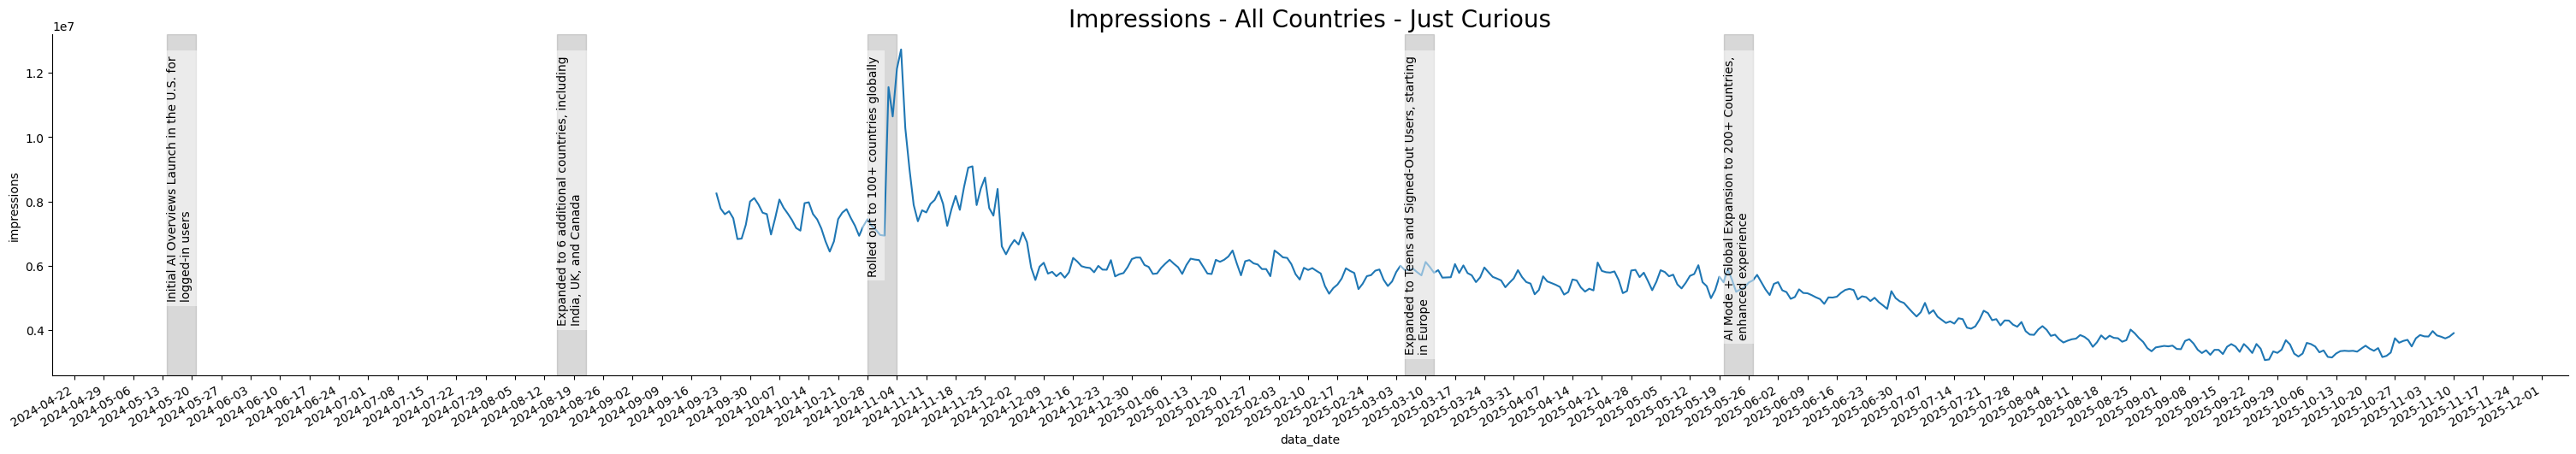

In [19]:
# Get the number of impressions by date for USA, UK, and EU

query = (
    """
    # Get the number of impressions by date for USA, UK, and EU for Just Curious articles

    WITH countries as
    (
      SELECT
          country_code
          , geo_region
        , country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    , data as
    (
      SELECT
          gsc.data_date
        #, SUM(gsc.impressions) as impressions
        , impressions
        , country_code
        , country_name
        , geo_region
        , gsc.url
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN `gannett-datascience.sesame.just-curious-2025-09-29` jc
        ON gsc.url = jc.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
    )

    SELECT data_date
      , SUM(impressions) as impressions
    FROM data
    GROUP BY
        data_date
    ORDER BY data_date
    """
)

df_impressions_jc = client.query_and_wait(query).to_dataframe()
df_impressions_jc.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_jc, 'impressions', ax, title_suffix="All Countries - Just Curious", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

----

##Page Views

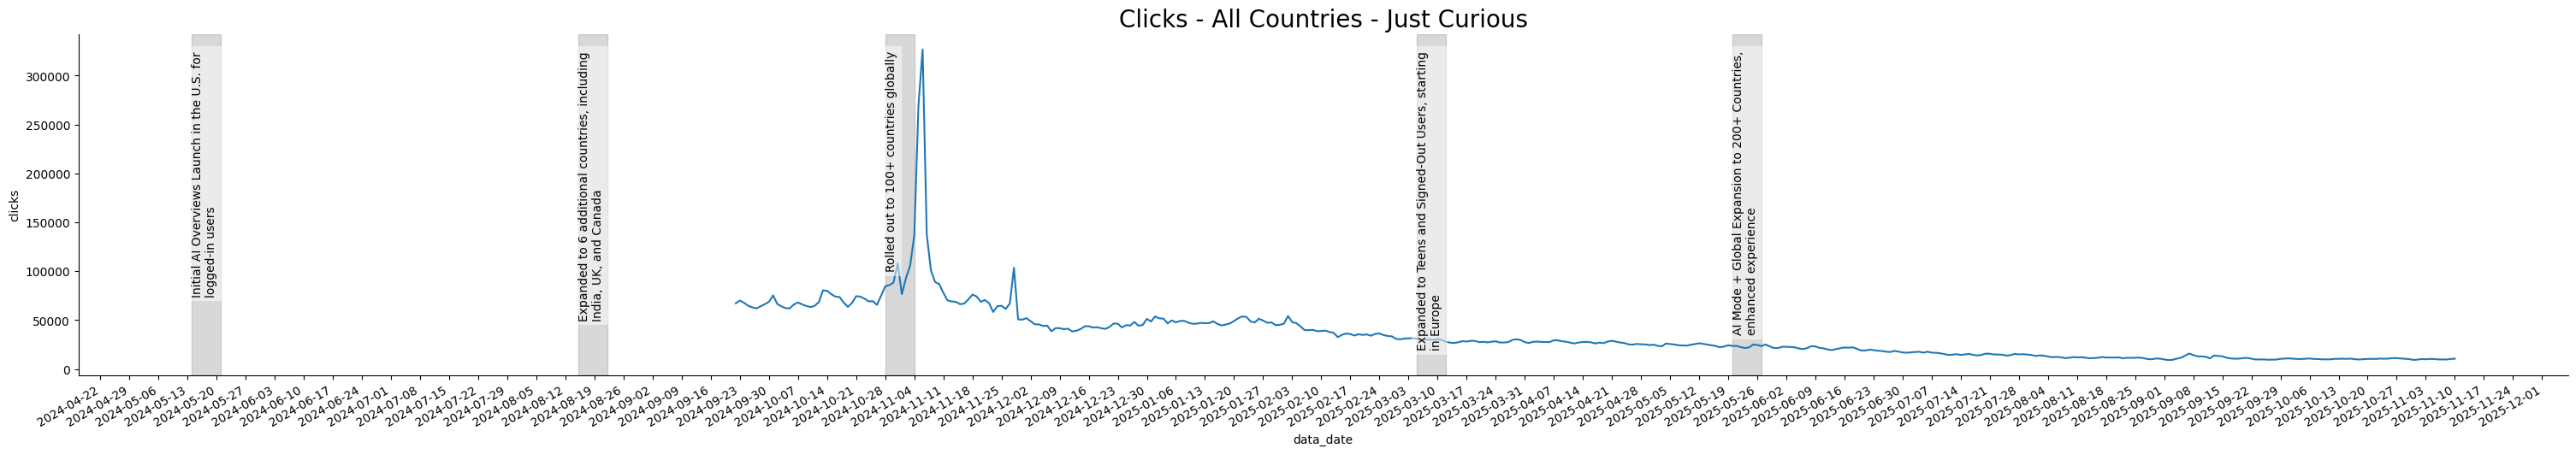

In [21]:
# Get the number of clicks by date for USA, UK, and EU

query = (
    """
    # Get the number of clicks by date for USA, UK, and EU for Just Curious articles

    WITH countries as
    (
      SELECT
          country_code
          , geo_region
        , country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    , data as
    (
      SELECT
          gsc.data_date
        #, SUM(gsc.impressions) as impressions
        , clicks
        , country_code
        , country_name
        , geo_region
        , gsc.url
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN `gannett-datascience.sesame.just-curious-2025-09-29` jc
        ON gsc.url = jc.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
    )

    SELECT data_date
      , SUM(clicks) as clicks
    FROM data
    GROUP BY
        data_date
    ORDER BY data_date
    """
)

df_clicks_jc = client.query_and_wait(query).to_dataframe()
df_clicks_jc.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_clicks_jc, 'clicks', ax, title_suffix="All Countries - Just Curious", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

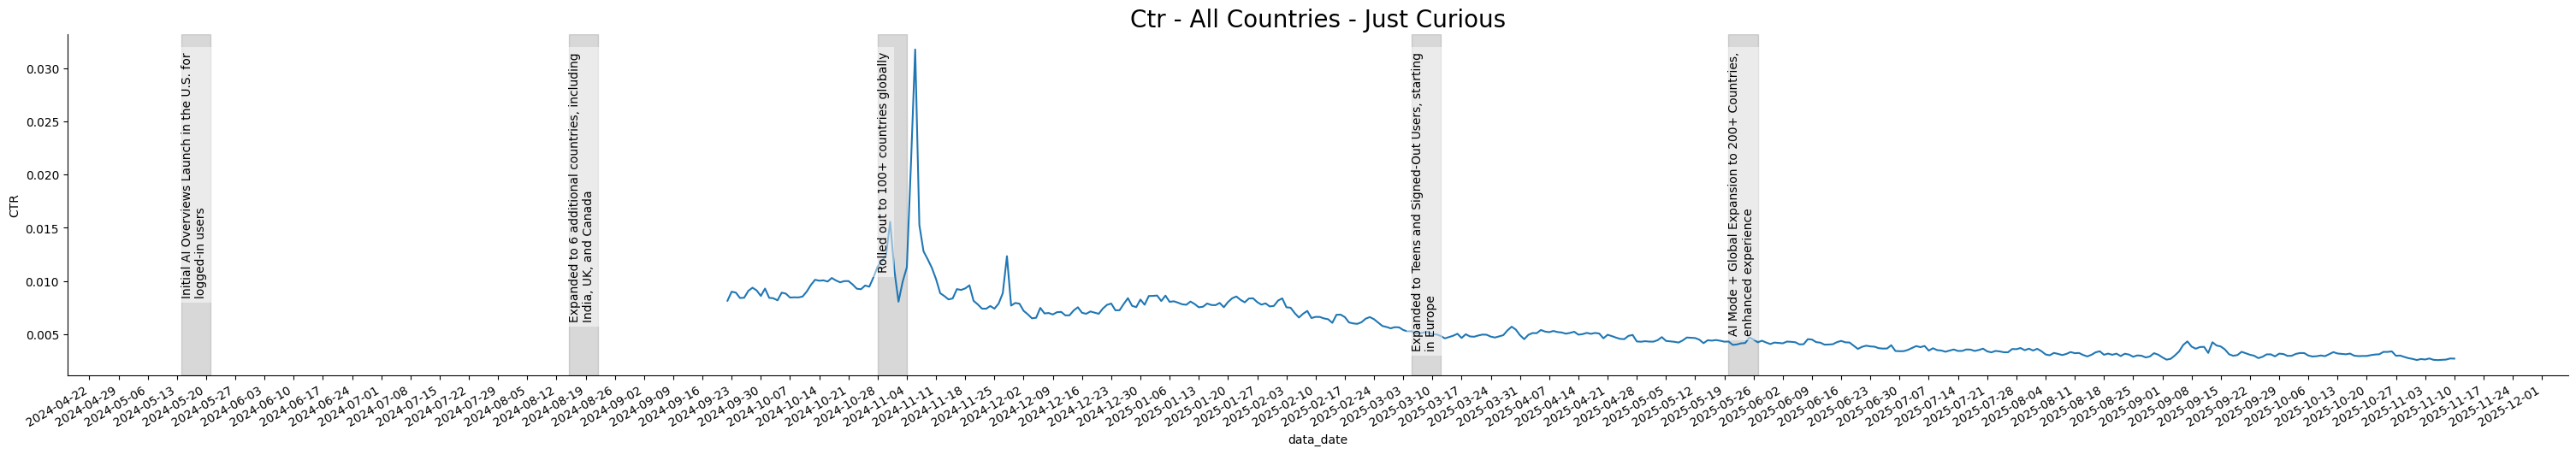

In [22]:
# Get the click through rate by date for USA, UK, and EU

query = (
    """
    # Get the CTR by date for USA, UK, and EU for Just Curious articles

    WITH countries as
    (
      SELECT
          country_code
          , geo_region
        , country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    , data as
    (
      SELECT
          gsc.data_date
        #, SUM(gsc.impressions) as impressions
        , impressions
        , clicks
        , country_code
        , country_name
        , geo_region
        , gsc.url
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN `gannett-datascience.sesame.just-curious-2025-09-29` jc
        ON gsc.url = jc.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
    )

    SELECT data_date
      , SUM(clicks)/SUM(impressions) as CTR
    FROM data
    GROUP BY
        data_date
    ORDER BY data_date
    """
)

df_impressions_jc = client.query_and_wait(query).to_dataframe()
df_impressions_jc.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_jc, 'CTR', ax, title_suffix="All Countries - Just Curious", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

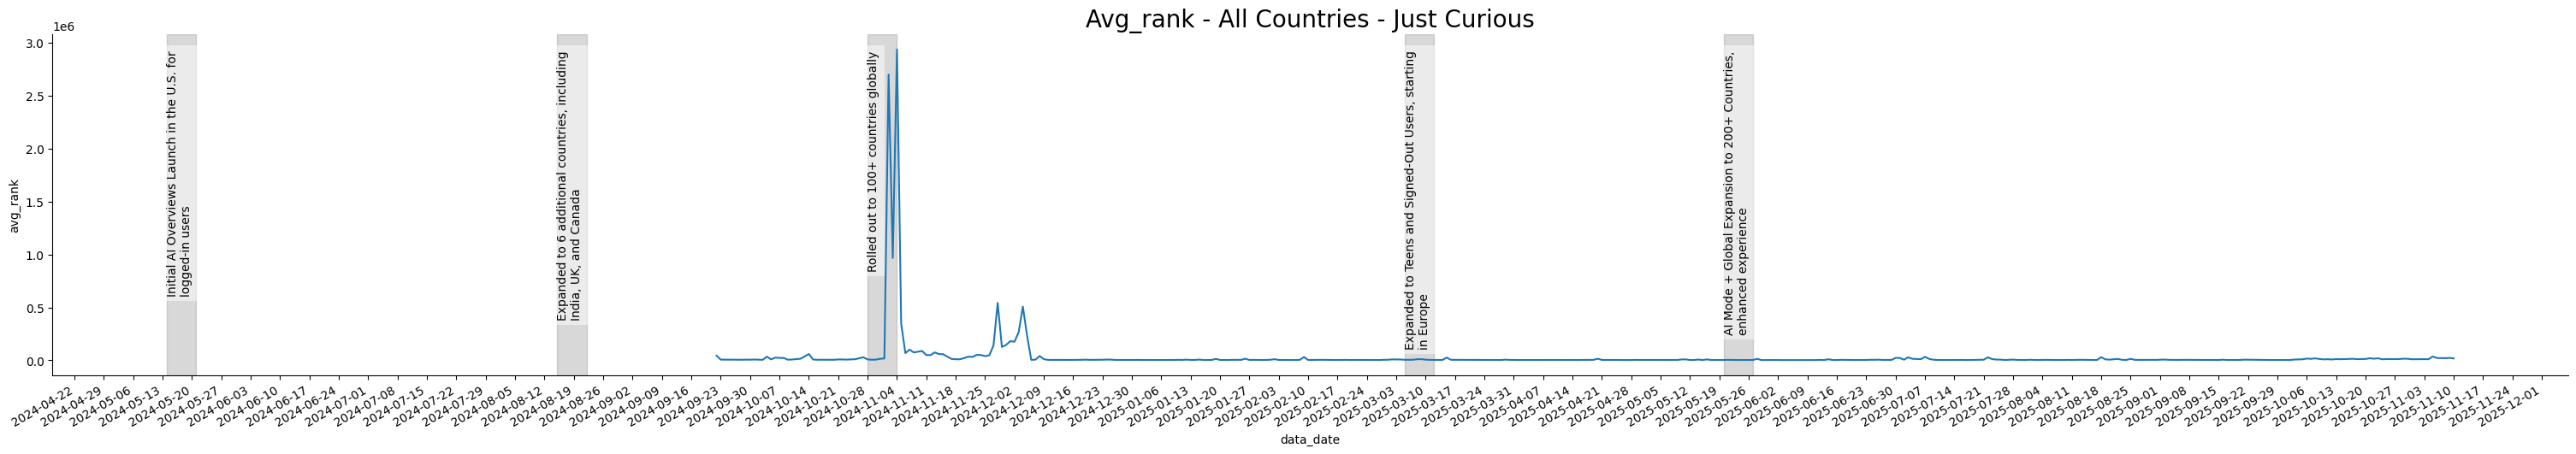

In [23]:
# Get the average rank by date for USA, UK, and EU

query = (
    """
    # Get the CTR by date for USA, UK, and EU for Just Curious articles

    WITH countries as
    (
      SELECT
          country_code
          , geo_region
        , country_name
      FROM `gannett-datascience.sesame.country_codes`
      #WHERE geo_region IN ('USA', 'UK', 'EU')
    )

    , data as
    (
      SELECT
          gsc.data_date
        #, SUM(gsc.impressions) as impressions
        , impressions
        , sum_position
        , country_code
        , country_name
        , geo_region
        , gsc.url
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN `gannett-datascience.sesame.just-curious-2025-09-29` jc
        ON gsc.url = jc.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
    )

    SELECT data_date
      #, (SUM(value * weight)) / SUM(weight)
      , (SUM(sum_position * impressions)) / SUM(impressions) as avg_rank
      #, AVG(sum_position) as avg_rank
    FROM data
    GROUP BY
        data_date
    ORDER BY data_date
    """
)

df_impressions_jc = client.query_and_wait(query).to_dataframe()
df_impressions_jc.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions_jc, 'avg_rank', ax, title_suffix="All Countries - Just Curious", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

---

# Filtering for content


In [ ]:
# @title
ssts_dict = {
    "section": "news",
    "subsection": "national",
    "topic": "",
    "subtopic": "",
}

def add_ssts(add_filter=True):
  where_append = ""
  if add_filter:
    for key in ssts_dict:
      if ssts_dict[key] == "":
        pass
      else:
        value = ssts_dict[key]
        where_append = where_append + f"AND {key} = '{value}'"
        print(where_append)
        return where_append
  else:
    return where_append


name = "Alice"
age = 30
message = f"Hello, my name is {name} and I am {age} years old."
#print(message)





query = (
  """
    WITH
      content_assets as
      (# Grab the SSTS lavels and the tag for whether something is evergreen
        SELECT pageURL.long as url  # We're going to use the long URL instead of the canonicalURL because the canonicalURL has things that aren't USA Today content like 10 best
          , COALESCE(classificationV2.section, ssts.section) as section
          , COALESCE(classificationV2.subsection, ssts.subsection) as subsection
          , COALESCE(classificationV2.topic, ssts.topic) as topic
          , COALESCE(classificationV2.subtopic, ssts.subtopic) as subtopic
          , isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  # Some values have 'USATODAY' and some have 'USA TODAY'
          AND pageURL.long LIKE '%www.%'  # Filter for only the www sites
          #AND section = "sports"
          #AND subsection = "mlb"
          #AND topic = "columnist"
          #AND subtopic = "bob-nightengale"
          #AND isEvergreen = false
        GROUP BY 1,2,3,4,5,6
      )

      , countries as
      (
        SELECT
            country_code
          --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        #WHERE geo_region IN ('USA', 'UK', 'EU')
      )

      SELECT
          gsc.data_date
        , SUM(gsc.impressions) as impressions
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN content_assets
        ON gsc.url = content_assets.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
      GROUP BY
          gsc.data_date
  """
)

print(query)


      WITH 
    content_assets as
    (# Grab the SSTS lavels and the tag for whether something is evergreen
      SELECT pageURL.long as url  # We're going to use the long URL instead of the canonicalURL because the canonicalURL has things that aren't USA Today content like 10 best
        , COALESCE(classificationV2.section, ssts.section) as section
        , COALESCE(classificationV2.subsection, ssts.subsection) as subsection
        , COALESCE(classificationV2.topic, ssts.topic) as topic
        , COALESCE(classificationV2.subtopic, ssts.subtopic) as subtopic
        , isEvergreen
      FROM `gannett-enterprise-data.content_prz.content_assets` 
      WHERE assetGroup.siteId = '1'
        AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  # Some values have 'USATODAY' and some have 'USA TODAY'
        AND pageURL.long LIKE '%www.%'  # Filter for only the www sites
        AND section = "news"
        AND subsection = ""
        AND topic = ""
        AND subtopic = ""
     

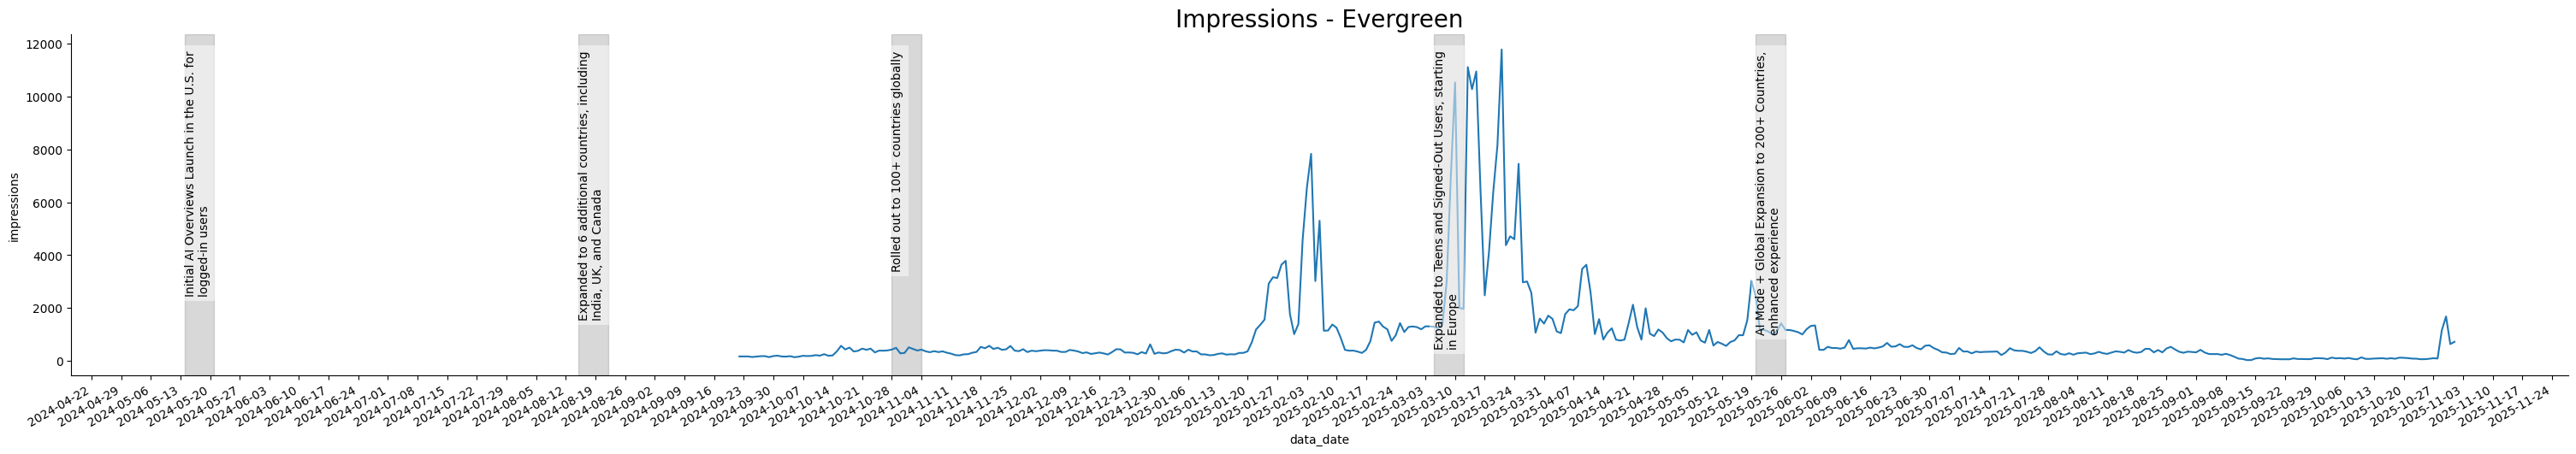

In [ ]:
query =(
    """
    WITH
      content_assets_raw as
      (# Grab the SSTS levels and the tag for whether something is evergreen
        SELECT pageURL.long as url  # We're going to use the long URL instead of the canonicalURL because the canonicalURL has things that aren't USA Today content like 10 best
          , COALESCE(classificationV2.section, ssts.section) as section
          , COALESCE(classificationV2.subsection, ssts.subsection) as subsection
          , COALESCE(classificationV2.topic, ssts.topic) as topic
          , COALESCE(classificationV2.subtopic, ssts.subtopic) as subtopic
          , isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  # Some values have 'USATODAY' and some have 'USA TODAY'
          AND pageURL.long LIKE '%www.%'  # Filter for only the www sites
        GROUP BY 1,2,3,4,5,6
      )

      , content_assets as
      (#Add a way to filter for content assets
        SELECT *
        FROM content_assets_raw
        WHERE
              section = "tech"
          #AND subsection = "mlb"
          #AND topic = "columnist"
          #AND subtopic = "bob-nightengale"
          AND
              isEvergreen = true
      )

      , countries as
      (
        SELECT
            country_code
          --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        #WHERE geo_region IN ('USA', 'UK', 'EU')
      )

      SELECT
          gsc.data_date
        , SUM(gsc.impressions) as impressions
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN content_assets
        ON gsc.url = content_assets.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
      GROUP BY
          gsc.data_date
    """
)

df_impressions = client.query_and_wait(query).to_dataframe()
df_impressions.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_impressions, 'impressions', ax, title_suffix="Evergreen", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

Big Difference:
*   Life *
*   Tech *
*   Money

Maybe:
*   Entertainment *
*   News
*   Shopping
*   Travel

NameError: name '_plot_series' is not defined

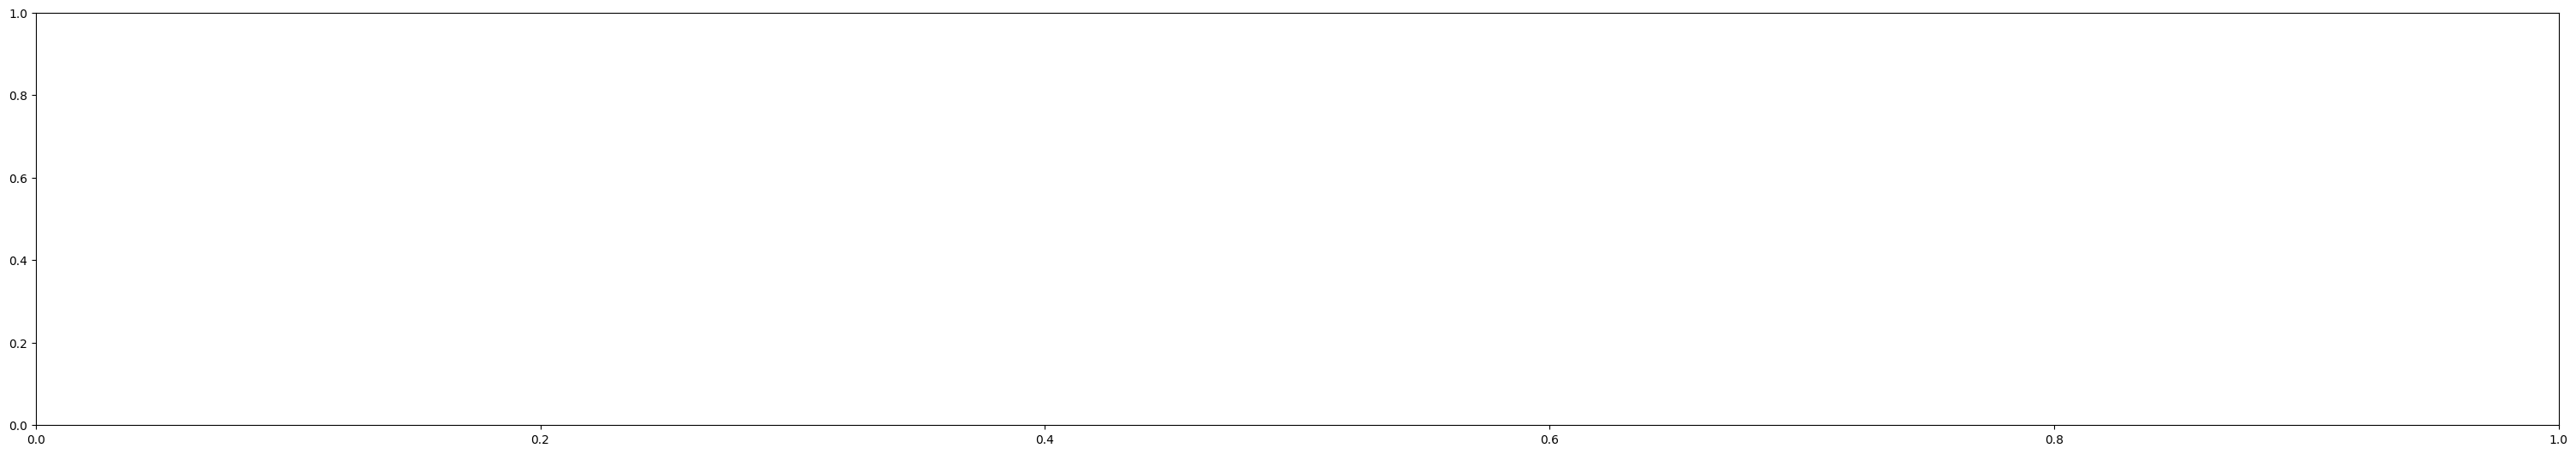

In [2]:
# This is for the clicks chart
query =(
    """
    WITH
      content_assets_raw as
      (# Grab the SSTS lavels and the tag for whether something is evergreen
        SELECT pageURL.long as url  # We're going to use the long URL instead of the canonicalURL because the canonicalURL has things that aren't USA Today content like 10 best
          , COALESCE(classificationV2.section, ssts.section) as section
          , COALESCE(classificationV2.subsection, ssts.subsection) as subsection
          , COALESCE(classificationV2.topic, ssts.topic) as topic
          , COALESCE(classificationV2.subtopic, ssts.subtopic) as subtopic
          , isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  # Some values have 'USATODAY' and some have 'USA TODAY'
          AND pageURL.long LIKE '%www.%'  # Filter for only the www sites
        GROUP BY 1,2,3,4,5,6
      )

      , content_assets as
      (#Add a way to filter for content assets
        SELECT *
        FROM content_assets_raw
        WHERE
              section = "tech"
          #AND subsection = "mlb"
          #AND topic = "columnist"
          #AND subtopic = "bob-nightengale"
          AND
              isEvergreen = true
      )

      , countries as
      (
        SELECT
            country_code
          --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        #WHERE geo_region IN ('USA', 'UK', 'EU')
      )

      SELECT
          gsc.data_date
        , SUM(gsc.clicks) as clicks
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN content_assets
        ON gsc.url = content_assets.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
      GROUP BY
          gsc.data_date
    """
)

df_clicks = client.query_and_wait(query).to_dataframe()
df_clicks.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_clicks, 'clicks', ax, title_suffix="Evergreen", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

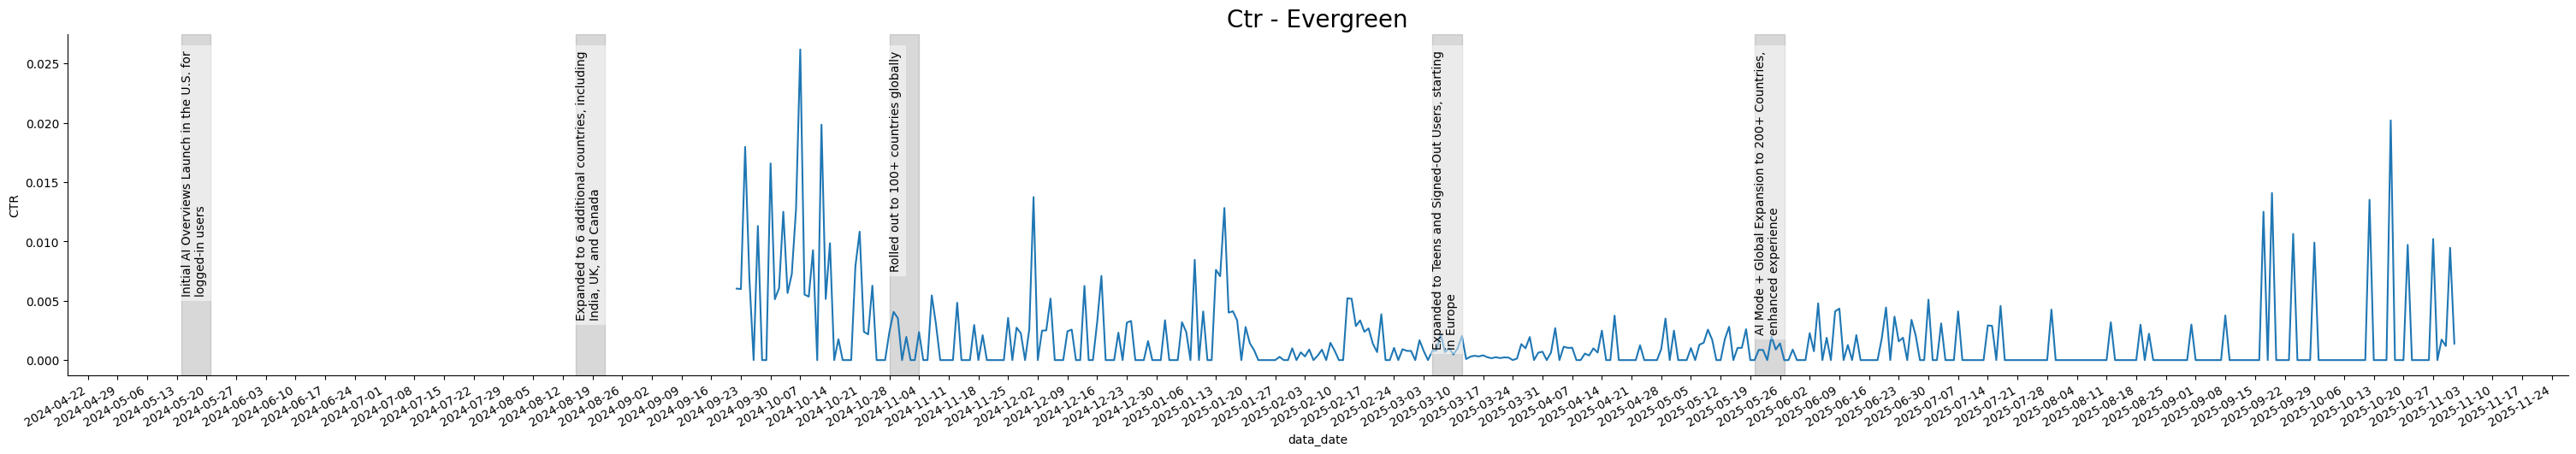

In [ ]:
# This is for the CTR chart
query =(
    """
    WITH
      content_assets_raw as
      (# Grab the SSTS lavels and the tag for whether something is evergreen
        SELECT pageURL.long as url  # We're going to use the long URL instead of the canonicalURL because the canonicalURL has things that aren't USA Today content like 10 best
          , COALESCE(classificationV2.section, ssts.section) as section
          , COALESCE(classificationV2.subsection, ssts.subsection) as subsection
          , COALESCE(classificationV2.topic, ssts.topic) as topic
          , COALESCE(classificationV2.subtopic, ssts.subtopic) as subtopic
          , isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  # Some values have 'USATODAY' and some have 'USA TODAY'
          AND pageURL.long LIKE '%www.%'  # Filter for only the www sites
        GROUP BY 1,2,3,4,5,6
      )

      , content_assets as
      (#Add a way to filter for content assets
        SELECT *
        FROM content_assets_raw
        WHERE
              section = "tech"
          #AND subsection = "mlb"
          #AND topic = "columnist"
          #AND subtopic = "bob-nightengale"
          AND
              isEvergreen = true
      )

      , countries as
      (
        SELECT
            country_code
          --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        #WHERE geo_region IN ('USA', 'UK', 'EU')
      )

      SELECT
          gsc.data_date
        , SUM(clicks)/SUM(gsc.impressions) as CTR
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN content_assets
        ON gsc.url = content_assets.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
      GROUP BY
          gsc.data_date
    """
)

df_ctr = client.query_and_wait(query).to_dataframe()
df_ctr.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_ctr, 'CTR', ax, title_suffix="Evergreen", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

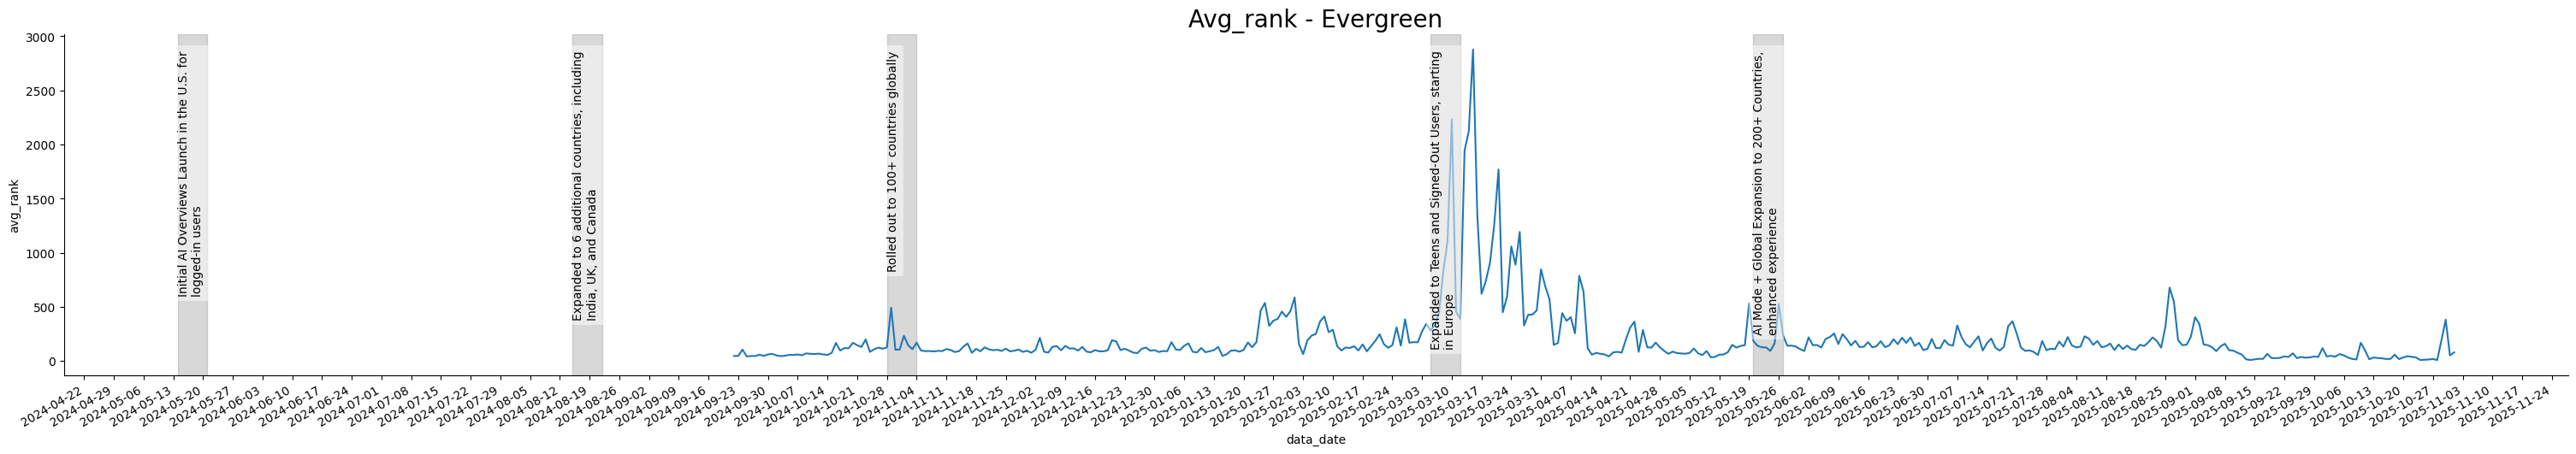

In [ ]:
#This is for the page rank chart w/ no modifications
query =(
    """
    WITH
      content_assets_raw as
      (# Grab the SSTS lavels and the tag for whether something is evergreen
        SELECT pageURL.long as url  # We're going to use the long URL instead of the canonicalURL because the canonicalURL has things that aren't USA Today content like 10 best
          , COALESCE(classificationV2.section, ssts.section) as section
          , COALESCE(classificationV2.subsection, ssts.subsection) as subsection
          , COALESCE(classificationV2.topic, ssts.topic) as topic
          , COALESCE(classificationV2.subtopic, ssts.subtopic) as subtopic
          , isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  # Some values have 'USATODAY' and some have 'USA TODAY'
          AND pageURL.long LIKE '%www.%'  # Filter for only the www sites
        GROUP BY 1,2,3,4,5,6
      )

      , content_assets as
      (#Add a way to filter for content assets
        SELECT *
        FROM content_assets_raw
        WHERE
              section = "tech"
          #AND subsection = "mlb"
          #AND topic = "columnist"
          #AND subtopic = "bob-nightengale"
          AND
              isEvergreen = true
      )

      , countries as
      (
        SELECT
            country_code
          --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        #WHERE geo_region IN ('USA', 'UK', 'EU')
      )

      SELECT
          gsc.data_date
        , (SUM(sum_position * impressions)) / SUM(impressions) as avg_rank
      FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
      INNER JOIN countries
        ON gsc.country = countries.country_code
      INNER JOIN content_assets
        ON gsc.url = content_assets.url
      WHERE --gsc.data_date BETWEEN '2025-09-01' and '2025-09-02'AND
            gsc.search_type = 'WEB'
      GROUP BY
          gsc.data_date
    """
)

df_avg_rank = client.query_and_wait(query).to_dataframe()
df_avg_rank.head(5)

fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
_plot_series(df_avg_rank, 'avg_rank', ax, title_suffix="Evergreen", events=event_ranges)
fig.autofmt_xdate() # Auto format the dates on the x-axis
sns.despine(fig=fig, ax=ax)

---
## USAT Sections + isEvergreen Combination

In [26]:
# Get the distinct combinations of section and isEvergreen status
sections_isEvergreen_query = (
    """
      SELECT
          section
        , isEvergreen
      FROM `gannett-datascience.sesame.USAT_ssts_evergreen`
      GROUP BY
          section
        , isEvergreen
    """
)

combos_df = client.query_and_wait(sections_isEvergreen_query).to_dataframe()
combos_df

,section,isEvergreen
0,None,False
1,None,True
2,aerial-journalism,False
3,augmented-reality,False
4,augmented-reality,True
5,cars,False
6,college,False
7,community-hub,False
8,entertainment,False
9,entertainment,True


In [23]:
# --- 2) Metric-specific SQL builder (parameterized query to avoid string injection) ---
METRIC_SELECT = {
    # Sum metrics
    "impressions": "SUM(gsc.impressions) AS impressions",
    "clicks": "SUM(gsc.clicks) AS clicks",
    # Rate/position metrics
    "CTR": "SAFE_DIVIDE(SUM(gsc.clicks), SUM(gsc.impressions)) AS CTR",
    "avg_rank": "SAFE_DIVIDE(SUM(sum_position * impressions), SUM(impressions)) AS avg_rank",
}

def build_sql(metric_key: str) -> str:
    """
    Returns a parameterized SQL string for the given metric.
    Uses @section and @isEvergreen bound parameters (set in job_config below).
    """
    metric_expr = METRIC_SELECT[metric_key]
    return f"""
    WITH
      content_assets_raw AS (
        -- Grab the SSTS levels and the tag for whether something is evergreen
        SELECT
          pageURL.long AS url,  -- Use long URL; canonical can include non-USA TODAY content (e.g., 10Best)
          COALESCE(classificationV2.section, ssts.section) AS section,
          COALESCE(classificationV2.subsection, ssts.subsection) AS subsection,
          COALESCE(classificationV2.topic, ssts.topic) AS topic,
          COALESCE(classificationV2.subtopic, ssts.subtopic) AS subtopic,
          isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  -- Some values are 'USATODAY', some 'USA TODAY'
          AND pageURL.long LIKE '%www.%'                             -- Restrict to www sites
        GROUP BY 1,2,3,4,5,6
      ),

      content_assets AS (
        -- Filter to section + evergreen combo
        SELECT *
        FROM content_assets_raw
        WHERE section = @section
          AND isEvergreen = @isEvergreen
      ),

      countries AS (
        SELECT country_code
        -- , country_name
        FROM `gannett-datascience.sesame.country_codes`
        -- WHERE geo_region IN ('USA', 'UK', 'EU')
      )

    SELECT
      gsc.data_date,
      {metric_expr}
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    INNER JOIN countries
      ON gsc.country = countries.country_code
    INNER JOIN content_assets
      ON gsc.url = content_assets.url
    WHERE gsc.search_type = 'WEB'
    GROUP BY gsc.data_date
    ORDER BY gsc.data_date
    """


In [24]:
# --- 3) Helper: run a parameterized query for a metric/section/evergreen ---
def fetch_metric_df(section_val: str, evergreen_val: bool, metric_key: str) -> pd.DataFrame:
    sql = build_sql(metric_key)
    job_config = bigquery.QueryJobConfig(
        query_parameters=[
            bigquery.ScalarQueryParameter("section", "STRING", section_val),
            bigquery.ScalarQueryParameter("isEvergreen", "BOOL", bool(evergreen_val)),
        ]
    )
    # Using client.query(...) instead of client.query_and_wait(...) so we can pass job_config
    job = client.query(sql, job_config=job_config)
    return job.result().to_dataframe()


In [15]:
# --- 4) Helper: safe filenames ---
from pathlib import Path
import re

# Where to save PNGs (change if you want a different folder)
output_dir = Path("charts_by_section_isEvergreen")
output_dir.mkdir(parents=True, exist_ok=True)

Path(output_dir).mkdir(parents=True, exist_ok=True)

def slugify(value: str) -> str:
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]+", "-", value)
    return re.sub(r"-+", "-", value).strip("-")

In [36]:
# --- 5) Plot all four metrics for every (section, isEvergreen) combo from the sheet ---
metric_order = ["impressions", "clicks", "CTR", "avg_rank"]  # controls plotting order & file naming

for section_val, evergreen_val in combos_df.itertuples(index=False):
    combo_slug = f"{slugify(section_val)}__evergreen-{str(bool(evergreen_val)).lower()}"
    print(f"\nProcessing: section='{section_val}', isEvergreen={evergreen_val} -> slug={combo_slug}")

    for metric_key in metric_order:
        # 5a) Query
        try:
            df_metric = fetch_metric_df(section_val, evergreen_val, metric_key)
        except Exception as e:
            print(f"  [ERROR] Query failed for {section_val} | {evergreen_val} | {metric_key}: {e}")
            continue

        if df_metric.empty:
            print(f"  [SKIP] No rows for {section_val} | {evergreen_val} | {metric_key}")
            continue

        # 5b) Plot
        try:
            fig, ax = plt.subplots(figsize=(30, 5.2), layout='constrained')
            _plot_series(
                df_metric,
                metric_key if metric_key in ["CTR", "avg_rank"] else metric_key,  # column names match keys
                ax,
                title_suffix=f"{section_val} | evergreen={evergreen_val}",
                events=event_ranges
            )
            fig.autofmt_xdate()
            sns.despine(fig=fig, ax=ax)

            # 5c) Save file
            out_path = Path(output_dir) / f"{metric_key}_{combo_slug}.png"
            fig.savefig(out_path, dpi=200, bbox_inches="tight")
            plt.close(fig)
            print(f"  [OK] Saved: {out_path}")
        except Exception as e:
            print(f"  [ERROR] Plot failed for {section_val} | {evergreen_val} | {metric_key}: {e}")
            plt.close("all")


Processing: section='None', isEvergreen=False -> slug=none__evergreen-false
  [SKIP] No rows for None | False | impressions
  [SKIP] No rows for None | False | clicks
  [SKIP] No rows for None | False | CTR
  [SKIP] No rows for None | False | avg_rank

Processing: section='None', isEvergreen=True -> slug=none__evergreen-true
  [SKIP] No rows for None | True | impressions
  [SKIP] No rows for None | True | clicks
  [SKIP] No rows for None | True | CTR
  [SKIP] No rows for None | True | avg_rank

Processing: section='aerial-journalism', isEvergreen=False -> slug=aerial-journalism__evergreen-false
  [OK] Saved: charts_by_section_isEvergreen/impressions_aerial-journalism__evergreen-false.png
  [OK] Saved: charts_by_section_isEvergreen/clicks_aerial-journalism__evergreen-false.png
  [OK] Saved: charts_by_section_isEvergreen/CTR_aerial-journalism__evergreen-false.png
  [OK] Saved: charts_by_section_isEvergreen/avg_rank_aerial-journalism__evergreen-false.png

Processing: section='augmented-r

In [38]:
!zip charts_by_section_isEvergreen_USAT_allCountries.zip charts_by_section_isEvergreen_USAT_allCountries/*

  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_aerial-journalism__evergreen-false.png (deflated 14%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_augmented-reality__evergreen-false.png (deflated 15%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_augmented-reality__evergreen-true.png (deflated 14%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_cars__evergreen-false.png (deflated 17%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_entertainment__evergreen-false.png (deflated 16%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_entertainment__evergreen-true.png (deflated 13%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_experience__evergreen-false.png (deflated 21%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_graphics__evergreen-false.png (deflated 21%)
  adding: charts_by_section_isEvergreen_USAT_allCountries/avg_rank_grap

In [ ]:
!zip -r foldername.zip yourfolder/*

In [41]:
!gcloud storage cp charts_by_section_isEvergreen_USAT_allCountries.zip gs://sesame_lydia

Copying file://charts_by_section_isEvergreen_USAT_allCountries.zip to gs://sesame_lydia/charts_by_section_isEvergreen_USAT_allCountries.zip

Average throughput: 100.5MiB/s


In [ ]:
# @title
# === CONFIG YOU CONTROL ===
DATA_SOURCE_NAME = "USAT"                # <- appears in titles & filenames
output_dir_name = f"charts_by_section_{DATA_SOURCE_NAME}_allCountries"

# === SETUP ===
from pathlib import Path
import re
import matplotlib.dates as mdates
from matplotlib.ticker import NullLocator
from matplotlib.dates import WeekdayLocator, MO
from matplotlib.ticker import NullFormatter
from textwrap import fill


output_dir = Path(output_dir_name)
output_dir.mkdir(parents=True, exist_ok=True)

# Read distinct sections from BigQuery
sections_query = (
    """
      SELECT
          section
      FROM `gannett-datascience.sesame.USAT_ssts_evergreen`
      GROUP BY
          section
    """
)

sections_df = client.query_and_wait(sections_query).to_dataframe()

sections = (
    sections_df["section"]
    .dropna()
    .astype(str).str.strip()
    .drop_duplicates()
    .sort_values()
    .tolist()
)

def slugify(value: str) -> str:
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]+", "-", value)
    return re.sub(r"-+", "-", value).strip("-")

# === SINGLE QUERY THAT RETURNS ALL 4 METRICS ===
def build_sql_all_metrics() -> str:
    return """
    WITH
      content_assets_raw AS (
        -- Grab the SSTS levels and the tag for whether something is evergreen
        SELECT
          pageURL.long AS url,  -- Use long URL; canonical can include non-USA TODAY content (e.g., 10Best)
          COALESCE(classificationV2.section, ssts.section) AS section,
          COALESCE(classificationV2.subsection, ssts.subsection) AS subsection,
          COALESCE(classificationV2.topic, ssts.topic) AS topic,
          COALESCE(classificationV2.subtopic, ssts.subtopic) AS subtopic,
          isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  -- 'USATODAY' vs 'USA TODAY'
          AND pageURL.long LIKE '%www.%'                             -- Restrict to www sites
        GROUP BY 1,2,3,4,5,6
      ),

      content_assets AS (
        -- NOTE: no isEvergreen filter anymore
        SELECT *
        FROM content_assets_raw
        WHERE section = @section
      ),

      countries AS (
        SELECT country_code
        --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        -- WHERE geo_region IN ('USA', 'UK', 'EU')
      )

    SELECT
      gsc.data_date,
      SUM(gsc.impressions) AS impressions,
      SUM(gsc.clicks) AS clicks,
      SAFE_DIVIDE(SUM(gsc.clicks), SUM(gsc.impressions)) AS CTR,
      SAFE_DIVIDE(SUM(gsc.sum_position * gsc.impressions), SUM(gsc.impressions)) AS avg_rank
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    INNER JOIN countries
      ON gsc.country = countries.country_code
    INNER JOIN content_assets
      ON gsc.url = content_assets.url
    WHERE gsc.search_type = 'WEB'
    GROUP BY gsc.data_date
    ORDER BY gsc.data_date
    """

def fetch_section_timeseries(section_val: str) -> pd.DataFrame:
    sql = build_sql_all_metrics()
    job_config = bigquery.QueryJobConfig(
        query_parameters=[bigquery.ScalarQueryParameter("section", "STRING", section_val)]
    )
    job = client.query(sql, job_config=job_config)
    return job.result().to_dataframe()

# === Determine if the GSC event should or should not be included in the graph (excluded events will be in the footer) ===
def split_events_by_range(events, start_dt, end_dt):
    """
    events: list of (start, end, label)
    start_dt/end_dt: datetime bounds of the plotted data
    Returns (events_in_range, events_outside_range).
    In-range events are clipped to the data window.
    """
    if events is None or len(events) == 0:
        return [], []

    start_dt = pd.to_datetime(start_dt)
    end_dt   = pd.to_datetime(end_dt)

    in_range = []
    out_range = []

    for s, e, label in events:
        s = pd.to_datetime(s)
        e = pd.to_datetime(e)

        # Skip or push to out_range if dates are missing or reversed
        if pd.isna(s) or pd.isna(e) or e < s:
            out_range.append((s, e, label))
            continue

        # Entirely outside the window
        if e < start_dt or s > end_dt:
            out_range.append((s, e, label))
        else:
            # Clip to the window
            in_range.append((max(s, start_dt), min(e, end_dt), label))

    return in_range, out_range


def format_excluded_events_footer(events):
    """
    Build a single-line (wrapped) footer string for excluded events.
    """
    if not events:
        return ""
    parts = [f"• {label} ({s:%Y-%m-%d}–{e:%Y-%m-%d})" for s, e, label in events]
    text = "Events outside displayed range: " + "   ".join(parts)
    # Wrap to avoid running off the page
    return fill(text, width=160)


# === Format the x-axis (time axis on the bottom of the graph) ===
def format_time_axis(ax, date_series):
    """
    Make time axis readable:
    - Concise date labels
    - Reasonable number of ticks
    - Only show labels on bottom row via ax.label_outer() in caller
    """
    # Ensure datetime
    s = pd.to_datetime(date_series)
    ax.set_xlim(s.min(), s.max())

    # Primary: concise auto ticks
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    # Keep ticks from crowding
    ax.xaxis.set_minor_locator(NullLocator())
    ax.tick_params(axis='x', labelsize=9, rotation=0)


def format_time_axis_biweekly_iso(ax, date_series, anchor_weekday=MO):
    """
    Bottom x-axis on all subplots.
    Major ticks: every 2 weeks (anchor weekday), labels as YYYY-MM-DD at 45°.
    Minor ticks: every 1 week (anchor weekday), no labels.
    The RIGHT edge of each label is aligned to its tick mark.
    """
    s = pd.to_datetime(date_series)
    left, right = s.min(), s.max()
    ax.set_xlim(left, right)

    major = WeekdayLocator(byweekday=anchor_weekday, interval=2)
    minor = WeekdayLocator(byweekday=anchor_weekday, interval=1)

    ax.xaxis.set_major_locator(major)
    ax.xaxis.set_minor_locator(minor)

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.xaxis.set_minor_formatter(NullFormatter())  # hide minor labels

    # Bottom axis for all panels
    ax.xaxis.set_ticks_position('bottom')
    ax.tick_params(axis='x', which='both', labelbottom=True, bottom=True, top=False)

    # Make major ticks bigger than minor ticks
    ax.tick_params(axis='x', which='major', length=9, width=1.3)
    ax.tick_params(axis='x', which='minor', length=4, width=0.8)

    # Rotate labels 45° and anchor the RIGHT edge on the tick
    ax.tick_params(axis='x', labelrotation=45, pad=6)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')              # right edge sits on tick
        lbl.set_rotation_mode('anchor')  # keep anchor fixed while rotating
        # optional for aesthetics:
        # lbl.set_va('top')

    # avoid extra whitespace so ticks/labels reach the ends cleanly
    ax.margins(x=0)



# === 4-UP PLOTTING ===
import numpy as np
import matplotlib.pyplot as plt

def plot_fourpack(df: pd.DataFrame, section_val: str, events: list):
    # --- compute data window & split events
    data_dates = pd.to_datetime(df["data_date"])
    start_dt, end_dt = data_dates.min(), data_dates.max()
    events_in, events_out = split_events_by_range(events, start_dt, end_dt)
    footer = format_excluded_events_footer(events_out)

    panels = [
        ("impressions", "Impressions"),
        ("clicks", "Clicks"),
        ("CTR", "CTR"),
        ("avg_rank", "Average Rank"),
    ]

    if footer:
        # Figure with a bottom footer row
        fig = plt.figure(figsize=(32, 16), layout='constrained')
        gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.10])  # small row for footer
        # main axes (2x2), share x
        ax00 = fig.add_subplot(gs[0, 0])
        ax01 = fig.add_subplot(gs[0, 1], sharex=ax00)
        ax10 = fig.add_subplot(gs[1, 0], sharex=ax00)
        ax11 = fig.add_subplot(gs[1, 1], sharex=ax00)
        axes = np.array([[ax00, ax01], [ax10, ax11]])

        # footer axis spanning both columns
        ax_footer = fig.add_subplot(gs[2, :])
        ax_footer.axis('off')
        ax_footer.text(0.5, 0.5, footer, ha="center", va="center", fontsize=10, wrap=True)
    else:
        # Simple 2x2 without footer row
        fig, axes = plt.subplots(2, 2, figsize=(32, 16), layout='constrained', sharex=True)

    # --- plot panels
    for ax, (col, label) in zip(axes.flatten(), panels):
        if col not in df.columns:
            ax.set_title(f"{label} — no data"); ax.axis("off"); continue

        _plot_series(
            df, col, ax,
            title_suffix=f"{section_val} · {DATA_SOURCE_NAME}",
            events=events_in
        )

        # YYYY-MM-DD majors every 2 weeks; minors weekly; 45° labels, right-anchored;
        # major ticks larger than minor (your preferred formatter)
        format_time_axis_biweekly_iso(ax, df["data_date"])

        try:
            sns.despine(fig=fig, ax=ax, top=True, right=True)
        except Exception:
            pass

    fig.suptitle(f"{DATA_SOURCE_NAME} — Section: {section_val}", fontsize=18)
    return fig





# === DRIVE THE WHOLE THING ===
for section_val in sections:
    print(f"Processing 4-up for section: {section_val}")
    try:
        df_all = fetch_section_timeseries(section_val)
    except Exception as e:
        print(f"  [ERROR] Query failed for section '{section_val}': {e}")
        continue

    if df_all.empty:
        print(f"  [SKIP] No rows for section '{section_val}'.")
        continue

    try:
        fig = plot_fourpack(df_all, section_val, event_ranges)
        fname = f"{DATA_SOURCE_NAME}_section-{slugify(section_val)}_4up.png"
        fig.savefig(output_dir / fname, dpi=200, bbox_inches="tight")
        plt.close(fig)
        print(f"  [OK] Saved: {output_dir / fname}")
    except Exception as e:
        print(f"  [ERROR] Plot failed for section '{section_val}': {e}")
        plt.close("all")


---
## Separation by Section only - all countries

In [28]:
# @title
# === CONFIG YOU CONTROL ===
DATA_SOURCE_NAME = "USAT"                # <- appears in titles & filenames
output_dir_name = f"charts_by_section_{DATA_SOURCE_NAME}_allCountries"

# === SETUP ===
from pathlib import Path
import re
import matplotlib.dates as mdates
from matplotlib.ticker import NullLocator
from matplotlib.dates import WeekdayLocator, MO
from matplotlib.ticker import NullFormatter
from textwrap import fill


output_dir = Path(output_dir_name)
output_dir.mkdir(parents=True, exist_ok=True)

# Read distinct sections from BigQuery
sections_query = (
    """
      SELECT
          section
      FROM `gannett-datascience.sesame.USAT_ssts_evergreen`
      GROUP BY
          section
    """
)

sections_df = client.query_and_wait(sections_query).to_dataframe()

sections = (
    sections_df["section"]
    .dropna()
    .astype(str).str.strip()
    .drop_duplicates()
    .sort_values()
    .tolist()
)

def slugify(value: str) -> str:
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]+", "-", value)
    return re.sub(r"-+", "-", value).strip("-")

# === SINGLE QUERY THAT RETURNS ALL 4 METRICS ===
def build_sql_all_metrics() -> str:
    return """
    WITH
      content_assets_raw AS (
        -- Grab the SSTS levels and the tag for whether something is evergreen
        SELECT
          pageURL.long AS url,  -- Use long URL; canonical can include non-USA TODAY content (e.g., 10Best)
          COALESCE(classificationV2.section, ssts.section) AS section,
          COALESCE(classificationV2.subsection, ssts.subsection) AS subsection,
          COALESCE(classificationV2.topic, ssts.topic) AS topic,
          COALESCE(classificationV2.subtopic, ssts.subtopic) AS subtopic,
          isEvergreen
        FROM `gannett-enterprise-data.content_prz.content_assets`
        WHERE assetGroup.siteId = '1'
          AND REGEXP_REPLACE(assetGroup.Name, ' ', '') = 'USATODAY'  -- 'USATODAY' vs 'USA TODAY'
          AND pageURL.long LIKE '%www.%'                             -- Restrict to www sites
        GROUP BY 1,2,3,4,5,6
      ),

      content_assets AS (
        -- NOTE: no isEvergreen filter anymore
        SELECT *
        FROM content_assets_raw
        WHERE section = @section
      ),

      countries AS (
        SELECT country_code
        --, country_name
        FROM `gannett-datascience.sesame.country_codes`
        -- WHERE geo_region IN ('USA', 'UK', 'EU')
      )

    SELECT
      gsc.data_date,
      SUM(gsc.impressions) AS impressions,
      SUM(gsc.clicks) AS clicks,
      SAFE_DIVIDE(SUM(gsc.clicks), SUM(gsc.impressions)) AS CTR,
      SAFE_DIVIDE(SUM(gsc.sum_position * gsc.impressions), SUM(gsc.impressions)) AS avg_rank
    FROM `gannett-searchconsole-data.searchconsole_usatoday_com.searchdata_url_impression` gsc
    INNER JOIN countries
      ON gsc.country = countries.country_code
    INNER JOIN content_assets
      ON gsc.url = content_assets.url
    WHERE gsc.search_type = 'WEB'
    GROUP BY gsc.data_date
    ORDER BY gsc.data_date
    """

def fetch_section_timeseries(section_val: str) -> pd.DataFrame:
    sql = build_sql_all_metrics()
    job_config = bigquery.QueryJobConfig(
        query_parameters=[bigquery.ScalarQueryParameter("section", "STRING", section_val)]
    )
    job = client.query(sql, job_config=job_config)
    return job.result().to_dataframe()

# === Determine if the GSC event should or should not be included in the graph (excluded events will be in the footer) ===
def split_events_by_range(events, start_dt, end_dt):
    """
    events: list of (start, end, label)
    start_dt/end_dt: datetime bounds of the plotted data
    Returns (events_in_range, events_outside_range).
    In-range events are clipped to the data window.
    """
    if events is None or len(events) == 0:
        return [], []

    start_dt = pd.to_datetime(start_dt)
    end_dt   = pd.to_datetime(end_dt)

    in_range = []
    out_range = []

    for s, e, label in events:
        s = pd.to_datetime(s)
        e = pd.to_datetime(e)

        # Skip or push to out_range if dates are missing or reversed
        if pd.isna(s) or pd.isna(e) or e < s:
            out_range.append((s, e, label))
            continue

        # Entirely outside the window
        if e < start_dt or s > end_dt:
            out_range.append((s, e, label))
        else:
            # Clip to the window
            in_range.append((max(s, start_dt), min(e, end_dt), label))

    return in_range, out_range


def format_excluded_events_footer(events):
    """
    Build a single-line (wrapped) footer string for excluded events.
    """
    if not events:
        return ""
    parts = [f"• {label} ({s:%Y-%m-%d}–{e:%Y-%m-%d})" for s, e, label in events]
    text = "Events outside displayed range: " + "   ".join(parts)
    # Wrap to avoid running off the page
    return fill(text, width=160)


# === Format the x-axis (time axis on the bottom of the graph) ===
def format_time_axis(ax, date_series):
    """
    Make time axis readable:
    - Concise date labels
    - Reasonable number of ticks
    - Only show labels on bottom row via ax.label_outer() in caller
    """
    # Ensure datetime
    s = pd.to_datetime(date_series)
    ax.set_xlim(s.min(), s.max())

    # Primary: concise auto ticks
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    # Keep ticks from crowding
    ax.xaxis.set_minor_locator(NullLocator())
    ax.tick_params(axis='x', labelsize=9, rotation=0)


def format_time_axis_biweekly_iso(ax, date_series, anchor_weekday=MO):
    """
    Bottom x-axis on all subplots.
    Major ticks: every 2 weeks (anchor weekday), labels as YYYY-MM-DD at 45°.
    Minor ticks: every 1 week (anchor weekday), no labels.
    The RIGHT edge of each label is aligned to its tick mark.
    """
    s = pd.to_datetime(date_series)
    left, right = s.min(), s.max()
    ax.set_xlim(left, right)

    major = WeekdayLocator(byweekday=anchor_weekday, interval=2)
    minor = WeekdayLocator(byweekday=anchor_weekday, interval=1)

    ax.xaxis.set_major_locator(major)
    ax.xaxis.set_minor_locator(minor)

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.xaxis.set_minor_formatter(NullFormatter())  # hide minor labels

    # Bottom axis for all panels
    ax.xaxis.set_ticks_position('bottom')
    ax.tick_params(axis='x', which='both', labelbottom=True, bottom=True, top=False)

    # Make major ticks bigger than minor ticks
    ax.tick_params(axis='x', which='major', length=9, width=1.3)
    ax.tick_params(axis='x', which='minor', length=4, width=0.8)

    # Rotate labels 45° and anchor the RIGHT edge on the tick
    ax.tick_params(axis='x', labelrotation=45, pad=6)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')              # right edge sits on tick
        lbl.set_rotation_mode('anchor')  # keep anchor fixed while rotating
        # optional for aesthetics:
        # lbl.set_va('top')

    # avoid extra whitespace so ticks/labels reach the ends cleanly
    ax.margins(x=0)



# === 4-UP PLOTTING ===
import numpy as np
import matplotlib.pyplot as plt

def plot_fourpack(df: pd.DataFrame, section_val: str, events: list):
    # --- compute data window & split events
    data_dates = pd.to_datetime(df["data_date"])
    start_dt, end_dt = data_dates.min(), data_dates.max()
    events_in, events_out = split_events_by_range(events, start_dt, end_dt)
    footer = format_excluded_events_footer(events_out)

    panels = [
        ("impressions", "Impressions"),
        ("clicks", "Clicks"),
        ("CTR", "CTR"),
        ("avg_rank", "Average Rank"),
    ]

    if footer:
        # Figure with a bottom footer row
        fig = plt.figure(figsize=(32, 16), layout='constrained')
        gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.10])  # small row for footer
        # main axes (2x2), share x
        ax00 = fig.add_subplot(gs[0, 0])
        ax01 = fig.add_subplot(gs[0, 1], sharex=ax00)
        ax10 = fig.add_subplot(gs[1, 0], sharex=ax00)
        ax11 = fig.add_subplot(gs[1, 1], sharex=ax00)
        axes = np.array([[ax00, ax01], [ax10, ax11]])

        # footer axis spanning both columns
        ax_footer = fig.add_subplot(gs[2, :])
        ax_footer.axis('off')
        ax_footer.text(0.5, 0.5, footer, ha="center", va="center", fontsize=10, wrap=True)
    else:
        # Simple 2x2 without footer row
        fig, axes = plt.subplots(2, 2, figsize=(32, 16), layout='constrained', sharex=True)

    # --- plot panels
    for ax, (col, label) in zip(axes.flatten(), panels):
        if col not in df.columns:
            ax.set_title(f"{label} — no data"); ax.axis("off"); continue

        _plot_series(
            df, col, ax,
            title_suffix=f"{section_val} · {DATA_SOURCE_NAME}",
            events=events_in
        )

        # YYYY-MM-DD majors every 2 weeks; minors weekly; 45° labels, right-anchored;
        # major ticks larger than minor (your preferred formatter)
        format_time_axis_biweekly_iso(ax, df["data_date"])

        try:
            sns.despine(fig=fig, ax=ax, top=True, right=True)
        except Exception:
            pass

    fig.suptitle(f"{DATA_SOURCE_NAME} — Section: {section_val}", fontsize=18)
    return fig





# === DRIVE THE WHOLE THING ===
for section_val in sections:
    print(f"Processing 4-up for section: {section_val}")
    try:
        df_all = fetch_section_timeseries(section_val)
    except Exception as e:
        print(f"  [ERROR] Query failed for section '{section_val}': {e}")
        continue

    if df_all.empty:
        print(f"  [SKIP] No rows for section '{section_val}'.")
        continue

    try:
        fig = plot_fourpack(df_all, section_val, event_ranges)
        fname = f"{DATA_SOURCE_NAME}_section-{slugify(section_val)}_4up.png"
        fig.savefig(output_dir / fname, dpi=200, bbox_inches="tight")
        plt.close(fig)
        print(f"  [OK] Saved: {output_dir / fname}")
    except Exception as e:
        print(f"  [ERROR] Plot failed for section '{section_val}': {e}")
        plt.close("all")


Processing 4-up for section: aerial-journalism
  [OK] Saved: charts_by_section_USAT_allCountries/USAT_section-aerial-journalism_4up.png
Processing 4-up for section: augmented-reality
  [OK] Saved: charts_by_section_USAT_allCountries/USAT_section-augmented-reality_4up.png
Processing 4-up for section: cars
  [OK] Saved: charts_by_section_USAT_allCountries/USAT_section-cars_4up.png
Processing 4-up for section: college
  [SKIP] No rows for section 'college'.
Processing 4-up for section: community-hub
  [SKIP] No rows for section 'community-hub'.
Processing 4-up for section: entertainment
  [OK] Saved: charts_by_section_USAT_allCountries/USAT_section-entertainment_4up.png
Processing 4-up for section: experience
  [OK] Saved: charts_by_section_USAT_allCountries/USAT_section-experience_4up.png
Processing 4-up for section: graphics
  [OK] Saved: charts_by_section_USAT_allCountries/USAT_section-graphics_4up.png
Processing 4-up for section: grocery
  [OK] Saved: charts_by_section_USAT_allCountri

In [31]:
!zip charts_by_section_USAT_allCountries.zip charts_by_section_USAT_allCountries/*

  adding: charts_by_section_USAT_allCountries/USAT_section-aerial-journalism_4up.png (deflated 11%)
  adding: charts_by_section_USAT_allCountries/USAT_section-augmented-reality_4up.png (deflated 11%)
  adding: charts_by_section_USAT_allCountries/USAT_section-cars_4up.png (deflated 14%)
  adding: charts_by_section_USAT_allCountries/USAT_section-entertainment_4up.png (deflated 11%)
  adding: charts_by_section_USAT_allCountries/USAT_section-experience_4up.png (deflated 17%)
  adding: charts_by_section_USAT_allCountries/USAT_section-graphics_4up.png (deflated 12%)
  adding: charts_by_section_USAT_allCountries/USAT_section-grocery_4up.png (deflated 14%)
  adding: charts_by_section_USAT_allCountries/USAT_section-life_4up.png (deflated 15%)
  adding: charts_by_section_USAT_allCountries/USAT_section-marketplace_4up.png (deflated 15%)
  adding: charts_by_section_USAT_allCountries/USAT_section-money_4up.png (deflated 11%)
  adding: charts_by_section_USAT_allCountries/USAT_section-news_4up.png (d

In [32]:
!gcloud storage cp charts_by_section_USAT_allCountries.zip gs://sesame_lydia

Copying file://charts_by_section_USAT_allCountries.zip to gs://sesame_lydia/charts_by_section_USAT_allCountries.zip

Average throughput: 73.1MiB/s
